# Лабораторная работа № 1 — ЭТАЛОННОЕ РЕШЕНИЕ

## Однородные координаты и группа SE(3). Дерево систем координат

**Дисциплина:** Введение в технологии виртуальной дополненной реальности и робототехники
**Тема курса:** 2. Аффинная геометрия сцены. Однородные координаты и группа SE(3)

---

**Для преподавателя.** Не выдавать студентам до сдачи работы.

---

### Цель работы

Реализовать жёсткое преобразование трёхмерного пространства как элемент группы $SE(3)$,
проверить свойства группы численным экспериментом, построить дерево систем координат
и оценить накопление вычислительной погрешности при многократной композиции.

### Что понадобится

`numpy`, `matplotlib`. Ничего больше.

### Правило практикума

Алгоритм вы реализуете сами. Готовые функции из библиотек пространственных преобразований
(`scipy.spatial.transform`, `spatialmath`, `pytransform3d`) допустимо использовать **только**
для сверки собственного результата — и такую сверку нужно показать явно.

## Теоретическая справка

**Жёсткое преобразование** переводит точку $p \in \mathbb{R}^3$ в точку $Rp + t$, где
$R$ — матрица поворота, $t$ — вектор сдвига. Такое отображение не является линейным
(из-за сдвига), поэтому одной матрицей $3\times 3$ его не записать.

**Однородные координаты** решают эту проблему: точку $p = (x, y, z)$ представляют
четвёркой $(x, y, z, 1)$, а вектор (направление, разность точек) — четвёркой $(x, y, z, 0)$.
Тогда преобразование становится линейным и записывается матрицей $4\times4$:

$$
T \;=\;
\begin{pmatrix} R & t \\ 0^{\mathsf T} & 1 \end{pmatrix},
\qquad
R \in SO(3): \quad R^{\mathsf T} R = I, \;\; \det R = +1, \qquad t \in \mathbb{R}^3 .
$$

Множество таких матриц образует **группу** $SE(3)$ относительно умножения:

* композиция двух преобразований снова является преобразованием (замкнутость);
* умножение ассоциативно: $(AB)C = A(BC)$;
* нейтральный элемент — единичная матрица $I$;
* обратный элемент существует и вычисляется в замкнутой форме:

$$
T^{-1} = \begin{pmatrix} R^{\mathsf T} & -R^{\mathsf T} t \\ 0^{\mathsf T} & 1 \end{pmatrix}.
$$

Обратите внимание: обращать матрицу численно (`np.linalg.inv`) не нужно и не следует —
формула выше даёт точный результат за $O(1)$ операций.

Группа **некоммутативна**: $AB \ne BA$. Это не техническая деталь, а физический факт —
повернуть, а затем сдвинуть, и сдвинуть, а затем повернуть, приводит в разные точки.

**Дерево систем координат.** У робота каждое звено несёт свою систему координат, заданную
относительно родительской. Совокупность образует дерево с корнем в мировом кадре.
Преобразование между двумя произвольными кадрами получается перемножением матриц вдоль
пути через общего предка. Именно это делает библиотека TF2 в ROS.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)

## Задание 1. Элементарные повороты и класс преобразования

In [2]:
def rotx(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])


def roty(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])


def rotz(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])


class Transform:
    """Жёсткое преобразование как элемент SE(3), хранимое матрицей 4x4."""

    def __init__(self, matrix=None):
        self.M = np.eye(4) if matrix is None else np.asarray(matrix, dtype=float)
        if self.M.shape != (4, 4):
            raise ValueError('нужна матрица 4x4, получено %s' % (self.M.shape,))

    @classmethod
    def from_Rt(cls, R, t):
        M = np.eye(4)
        M[:3, :3] = R
        M[:3, 3] = np.asarray(t, dtype=float).ravel()
        return cls(M)

    @property
    def R(self):
        return self.M[:3, :3]

    @property
    def t(self):
        return self.M[:3, 3]

    def __matmul__(self, other):
        if isinstance(other, Transform):
            return Transform(self.M @ other.M)
        return NotImplemented

    def inverse(self):
        Rt = self.R.T
        return Transform.from_Rt(Rt, -Rt @ self.t)

    def apply_point(self, p):
        p = np.atleast_2d(np.asarray(p, dtype=float))
        h = np.hstack([p, np.ones((p.shape[0], 1))])
        return (h @ self.M.T)[:, :3].squeeze()

    def apply_vector(self, v):
        v = np.atleast_2d(np.asarray(v, dtype=float))
        h = np.hstack([v, np.zeros((v.shape[0], 1))])
        return (h @ self.M.T)[:, :3].squeeze()

    def __repr__(self):
        return 'Transform(\n%s)' % np.array2string(self.M, precision=4, suppress_small=True)

In [3]:
T = Transform.from_Rt(rotz(np.pi / 6) @ rotx(np.pi / 4), [1.0, -2.0, 0.5])
resid = np.linalg.norm((T @ T.inverse()).M - np.eye(4))
print('||T @ T^-1 - I|| = %.3e' % resid)
assert resid < 1e-12
print('OK')

||T @ T^-1 - I|| = 2.604e-16
OK


## Задание 2. Точка и вектор

**Ожидаемый вывод.** `apply_vector` игнорирует сдвиг: результат совпадает с $Rp$ точно
(разность — ноль, а не $10^{-16}$: четвёртая координата равна нулю, поэтому столбец сдвига
просто не участвует в скалярном произведении).

**Ответ на вопрос.** Как векторы преобразуются все величины, являющиеся *разностями точек*
или производными по времени: линейная и угловая скорость, сила, момент, нормаль к поверхности,
градиент. Как точки — только положения.

In [4]:
p = np.array([1.0, 0.0, 0.0])
print('точка  ->', T.apply_point(p))
print('вектор ->', T.apply_vector(p))
print('R @ p  ->', T.R @ p)
print()
print('|apply_point(p) - R p| = %.4f  (сдвиг влияет)' % np.linalg.norm(T.apply_point(p) - T.R @ p))
print('|apply_vector(p) - R p| = %.1e  (сдвиг не влияет)'
      % np.linalg.norm(T.apply_vector(p) - T.R @ p))

точка  -> [ 1.866 -1.5    0.5  ]
вектор -> [0.866 0.5   0.   ]
R @ p  -> [0.866 0.5   0.   ]

|apply_point(p) - R p| = 2.2913  (сдвиг влияет)
|apply_vector(p) - R p| = 0.0e+00  (сдвиг не влияет)


## Задание 3. Свойства группы

**Ожидаемые значения.** Ассоциативность $\sim10^{-15}$, некоммутативность — величина порядка
единиц (зависит от случайных сдвигов), замкнутость $\sim10^{-16}$.

**Ответ на вопрос.** $10^{-15}$ — это накопленная ошибка округления двойной точности:
машинный эпсилон $\approx 2{,}2\cdot10^{-16}$, а в произведении трёх матриц $4\times4$
выполняется несколько десятков сложений и умножений. Величина измеряет не «неточность теоремы»,
а точность арифметики с плавающей точкой.

In [5]:
def random_transform(rng):
    a, b, c = rng.uniform(-np.pi, np.pi, 3)
    return Transform.from_Rt(rotz(a) @ roty(b) @ rotx(c), rng.uniform(-3, 3, 3))


A, B, C = (random_transform(rng) for _ in range(3))

print('ассоциативность  ||(AB)C - A(BC)|| = %.3e' % np.linalg.norm(((A @ B) @ C).M - (A @ (B @ C)).M))
print('некоммутативность      ||AB - BA|| = %.4f' % np.linalg.norm((A @ B).M - (B @ A).M))
AB = A @ B
print('замкнутость         ||RᵀR - I|| = %.3e' % np.linalg.norm(AB.R.T @ AB.R - np.eye(3)))
print('                        det R    = %.12f' % np.linalg.det(AB.R))

ассоциативность  ||(AB)C - A(BC)|| = 1.799e-15
некоммутативность      ||AB - BA|| = 10.1690
замкнутость         ||RᵀR - I|| = 2.621e-16
                        det R    = 1.000000000000


**Геометрический контрпример к коммутативности** (его стоит требовать в отчёте):
поворот на 90° вокруг $z$ и сдвиг на 1 вдоль $x$. В одном порядке точка попадает в $(0,1,0)$,
в другом — в $(1,0,0)$.

In [6]:
Rz90 = Transform.from_Rt(rotz(np.pi / 2), [0, 0, 0])
Tx1 = Transform.from_Rt(np.eye(3), [1, 0, 0])
o = np.zeros(3)
print('сначала сдвиг, потом поворот:', (Rz90 @ Tx1).apply_point(o))
print('сначала поворот, потом сдвиг:', (Tx1 @ Rz90).apply_point(o))

сначала сдвиг, потом поворот: [0. 1. 0.]
сначала поворот, потом сдвиг: [1. 0. 0.]


## Задание 4. Дерево систем координат

**Ожидаемый результат:** положение `object` в кадре `camera` ≈ `[-0.0016, 0.6259, 0.1066]`
(при точном воспроизведении заданных в `LOCAL` значений).

**Типичная ошибка студентов** — перепутанный порядок в `world_from`: цепочку нужно
перемножать **от корня к листу**, то есть проходить `chain_to_root` в обратном порядке.
Признак ошибки: обе проверки в конце не проходят, а положение объекта выглядит правдоподобно.

In [7]:
PARENT = {'base': 'world', 'table': 'world', 'shoulder': 'base', 'elbow': 'shoulder',
          'wrist': 'elbow', 'camera': 'wrist', 'object': 'table'}

LOCAL = {
    'base':     Transform.from_Rt(rotz(0.30), [0.00, 0.00, 0.20]),
    'table':    Transform.from_Rt(np.eye(3),  [1.20, 0.40, 0.00]),
    'shoulder': Transform.from_Rt(roty(0.45), [0.00, 0.00, 0.35]),
    'elbow':    Transform.from_Rt(roty(-0.80), [0.40, 0.00, 0.00]),
    'wrist':    Transform.from_Rt(rotx(0.60), [0.35, 0.00, 0.00]),
    'camera':   Transform.from_Rt(rotz(-np.pi / 2) @ roty(np.pi / 2), [0.05, 0.00, 0.10]),
    'object':   Transform.from_Rt(rotz(1.10), [0.10, -0.15, 0.75]),
}


def chain_to_root(frame):
    path = [frame]
    while frame in PARENT:
        frame = PARENT[frame]
        path.append(frame)
    return path


def world_from(frame):
    Tw = Transform()
    for f in reversed(chain_to_root(frame)[:-1]):   # от корня к листу
        Tw = Tw @ LOCAL[f]
    return Tw


def lookup(target, source):
    """Преобразование, переводящее координаты из source в target."""
    return world_from(target).inverse() @ world_from(source)

In [8]:
T_cam_obj = lookup('camera', 'object')
print('цепочка от camera к корню:', chain_to_root('camera'))
print('положение object в кадре camera:', T_cam_obj.t)
print()

sym = np.linalg.norm((T_cam_obj @ lookup('object', 'camera')).M - np.eye(4))
print('проверка 1: ||lookup(a,b) @ lookup(b,a) - I|| = %.3e' % sym)

p_obj = np.zeros(3)
via_world = world_from('camera').inverse().apply_point(world_from('object').apply_point(p_obj))
print('проверка 2: расхождение с пересчётом через мир = %.3e'
      % np.linalg.norm(via_world - T_cam_obj.apply_point(p_obj)))

цепочка от camera к корню: ['camera', 'wrist', 'elbow', 'shoulder', 'base', 'world']
положение object в кадре camera: [-0.0016  0.6259  0.1066]

проверка 1: ||lookup(a,b) @ lookup(b,a) - I|| = 2.339e-16
проверка 2: расхождение с пересчётом через мир = 6.206e-17


## Задание 5. Визуализация

**На что смотреть при приёме работы.** Кадр `camera` должен быть повёрнут так, что его ось $z$
(оптическая ось) направлена «от схвата наружу», а не вдоль звена: композиция
$R_z(-\pi/2)\,R_y(\pi/2)$ переводит орт $e_z$ камеры в направление, совпадающее с осью $x$ запястья.
Это стандартное соглашение об оптическом кадре.

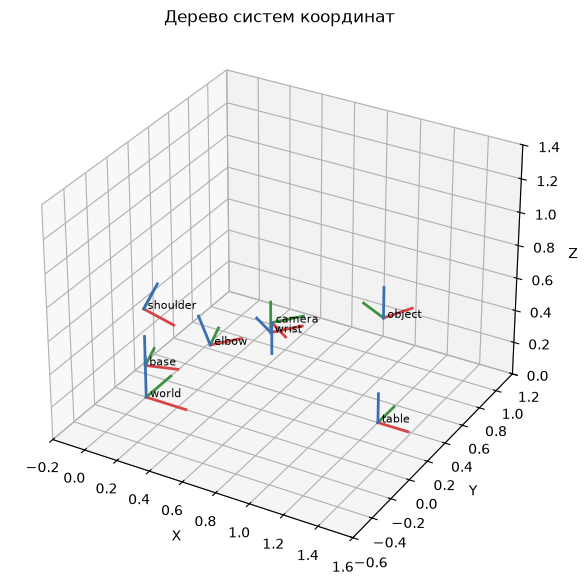

In [9]:
def draw_frame(ax, Tw, name, L=0.18):
    o = Tw.apply_point([0, 0, 0])
    for axis, col in zip(np.eye(3), ['#d64545', '#3f9142', '#3b6fb5']):
        e = Tw.apply_point(axis * L)
        ax.plot(*zip(o, e), color=col, lw=2)
    ax.text(*o, ' ' + name, fontsize=8)


fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection='3d')
draw_frame(ax, Transform(), 'world', L=0.25)
for f in LOCAL:
    draw_frame(ax, world_from(f), f)
ax.set_xlabel('X'); ax.set_ylabel('Y'); ax.set_zlabel('Z')
ax.set_xlim(-0.2, 1.6); ax.set_ylim(-0.6, 1.2); ax.set_zlim(0, 1.4)
ax.set_box_aspect((1.8, 1.8, 1.4))
ax.set_title('Дерево систем координат')
plt.tight_layout()
plt.show()

## Задание 6. Накопление погрешности

**Ожидаемый результат.** При $N = 10^5$ отклонение от единичной матрицы порядка $10^{-10}$,
то есть примерно $10^6$ машинных эпсилон. Наклон в двойном логарифмическом масштабе
получается около **1,3—1,4**.

**Разбор вопросов.**

* Наклон 1 отвечает росту $\propto N$ (систематическое накопление), наклон 0,5 — росту
  $\propto\sqrt N$ (независимые случайные ошибки, случайное блуждание).
* Полученный наклон заметно больше 0,5 — значит, ошибки накапливаются **не** независимо:
  каждая последующая композиция умножает уже искажённую матрицу, и погрешность переносится
  вперёд. Превышение единицы объясняется тем, что растёт и сама неортогональность $R$,
  что усиливает эффект.
* $10^{-10}$ метра — это $0{,}1$ нанометра при рабочей зоне в метр. Для робота погрешность
  совершенно несущественна: она на семь-восемь порядков меньше люфта редуктора и упругих
  деформаций звеньев. Практический вывод: **при обычной длине кинематической цепи об ошибках
  округления в SE(3) можно не думать**; проблема возникает лишь при интегрировании ориентации
  на протяжении миллионов шагов — там применяют периодическую ортогонализацию (задание 7).

In [10]:
Tstep = Transform.from_Rt(rotz(1e-3) @ rotx(7e-4), [1e-3, -2e-3, 5e-4])
Tinv = Tstep.inverse()

Ns = np.unique(np.round(np.logspace(1, 5, 25)).astype(int))
err_id, err_orth = [], []
for N in Ns:
    Tacc = Transform()
    for _ in range(N):
        Tacc = Tacc @ Tstep
    for _ in range(N):
        Tacc = Tacc @ Tinv
    err_id.append(np.linalg.norm(Tacc.M - np.eye(4)))
    err_orth.append(np.linalg.norm(Tacc.R.T @ Tacc.R - np.eye(3)))

err_id, err_orth = np.array(err_id), np.array(err_orth)
slope = np.polyfit(np.log10(Ns[err_id > 0]), np.log10(err_id[err_id > 0]), 1)[0]

print('при N = %d:  ||T_acc - I|| = %.2e  (%.0f eps)' % (Ns[-1], err_id[-1],
                                                        err_id[-1] / np.finfo(float).eps))
print('             ||RᵀR - I||  = %.2e' % err_orth[-1])
print('наклон log-log = %.2f' % slope)

при N = 100000:  ||T_acc - I|| = 2.51e-10  (1130848 eps)
             ||RᵀR - I||  = 1.09e-11
наклон log-log = 1.36


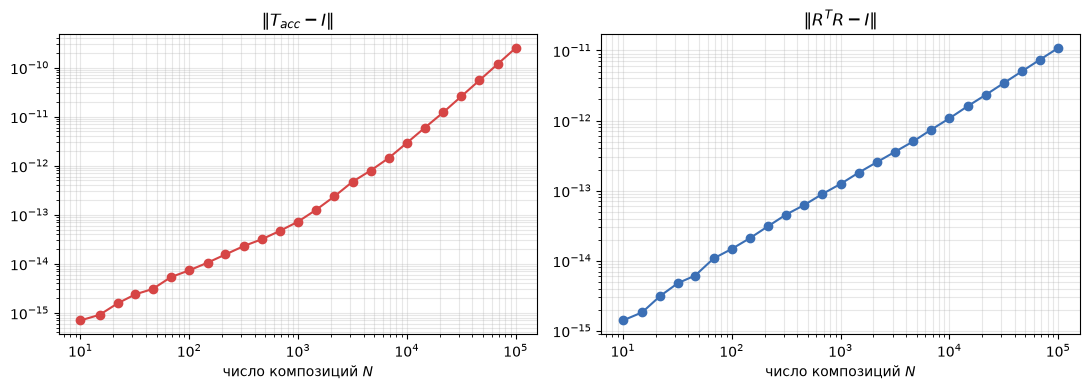

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].loglog(Ns, err_id, 'o-', color='#d64545')
axs[0].set_title(r'$\|T_{acc} - I\|$')
axs[1].loglog(Ns, np.maximum(err_orth, 1e-18), 'o-', color='#3b6fb5')
axs[1].set_title(r'$\|R^T R - I\|$')
for a in axs:
    a.set_xlabel('число композиций $N$')
    a.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

## Задание 7. Ортогонализация через SVD

**Ожидаемый результат.** Ошибка относительно истинной матрицы уменьшается примерно вдвое,
а неортогональность падает с $\sim10^{-3}$ до машинного нуля $\sim10^{-16}$.

Обратите внимание: SVD-проекция не «угадывает» истинную матрицу — она находит ближайшую
ортогональную. Часть шума, лежащая в касательном пространстве к $SO(3)$, остаётся.
Именно поэтому ошибка уменьшается, но не обращается в ноль.

In [12]:
R_true = rotz(0.7) @ roty(-0.3) @ rotx(1.1)
R_noisy = R_true + rng.normal(0, 2e-3, (3, 3))

U, S, Vt = np.linalg.svd(R_noisy)
R_fix = U @ np.diag([1, 1, np.sign(np.linalg.det(U @ Vt))]) @ Vt

print('сингулярные числа испорченной матрицы:', S)
print()
print('ошибка   до: %.2e   после: %.2e' % (np.linalg.norm(R_noisy - R_true),
                                           np.linalg.norm(R_fix - R_true)))
print('||RᵀR-I|| до: %.2e   после: %.2e' % (np.linalg.norm(R_noisy.T @ R_noisy - np.eye(3)),
                                            np.linalg.norm(R_fix.T @ R_fix - np.eye(3))))
print('det       до: %.6f    после: %.12f' % (np.linalg.det(R_noisy), np.linalg.det(R_fix)))

сингулярные числа испорченной матрицы: [1.0032 0.9993 0.9979]

ошибка   до: 4.51e-03   после: 2.34e-03
||RᵀR-I|| до: 7.72e-03   после: 6.87e-16
det       до: 1.000402    после: 1.000000000000


## Критерии приёма работы

| Что проверяется | На что смотреть |
|---|---|
| Задание 1 | `inverse()` реализован формулой, а не `np.linalg.inv`. Проверить явно в коде |
| Задание 2 | Есть численное подтверждение и содержательный ответ про скорости, силы, нормали |
| Задание 3 | Приведён **геометрический** контрпример, а не только норма разности |
| Задание 4 | Обе проверки пройдены. Порядок перемножения в `world_from` — от корня к листу |
| Задание 5 | Триэдры построены через `apply_point`; объяснена ориентация кадра `camera` |
| Задание 6 | Есть оценка наклона и вывод про систематическое накопление; результат переведён в eps |
| Выводы | Отвечено на все «вопросы для вывода» с конкретными числами |
| Воспроизводимость | «Restart & Run All» отрабатывает без ошибок |

**Частые ошибки:**

1. `inverse()` через `np.linalg.inv` — формально работает, но не засчитывается.
2. Перепутанный порядок в `world_from` — ловится проверкой 2 задания 4.
3. `apply_point` работает только для одной точки, падает на массиве $N\times3$.
4. В задании 6 берут линейный масштаб вместо логарифмического — график выглядит пустым.
5. В выводах пишут «погрешность мала», не приводя ни одного числа.

## Прикладной блок · SE(3) и дерево координат — это tf2 в ROS 2 *(необязательный)*

Понятия, собранные вручную в этой работе, в ROS 2 живут стеком **tf2**:

| Понятие из работы | Контрагент в ROS 2 |
|---|---|
| класс `Transform` (R\|t) | `tf2::Transform`, `geometry_msgs/TransformStamped`, `pinocchio.SE3` |
| словарь `PARENT` — дерево кадров | дерево `/tf`, которое рисует `ros2 run tf2_tools view_frames` |
| `lookup(a, b)` | `ros2 run tf2_ros tf2_echo a b`, `buffer.lookup_transform(...)` |
| `world_from(f)` — накопление цепочки | то, что `robot_state_publisher` собирает из URDF и публикует в `/tf` |

В контейнере `ros2` окружения курса то же дерево можно посмотреть вживую:

```bash
ros2 run robot_state_publisher robot_state_publisher \
  --ros-args -p robot_description:="$(cat /labs/docker/urdf/planar_3r.urdf)"
python3 docker/js_publisher.py   # живая метка времени; topic pub не годится
ros2 run tf2_ros tf2_echo link_ee link_base     # аналог lookup()
ros2 run tf2_tools view_frames                  # словарь PARENT в виде PDF
```

Ниже — численная сверка: наш `Transform` против `pinocchio.SE3` (Pinocchio —
библиотека кинематики из ROS-стека; ставится `pip install pin`). Блок
необязательный: без Pinocchio печатает подсказку и не ломает воспроизводимость
ноутбука «с нуля».

In [13]:
# Прикладной блок (необязательный): сверка Transform с pinocchio.SE3
try:
    import pinocchio as pin
except ImportError:
    pin = None

if pin is None:
    print('Pinocchio не установлен — блок пропущен.')
    print('Установка: pip install pin (или docker-окружение курса, docker/README.md).')
else:
    LOCAL_PIN = {k: pin.SE3(v.R, v.t) for k, v in LOCAL.items()}

    def world_from_pin(frame):
        T = pin.SE3.Identity()
        for f in reversed(chain_to_root(frame)[:-1]):
            T = T * LOCAL_PIN[f]
        return T

    # 1) групповая структура: цепочки pin.SE3 и Transform совпадают численно
    err_chain = max(np.linalg.norm(world_from_pin(f).homogeneous - world_from(f).M)
                    for f in LOCAL)
    print('композиция цепочек: max ||pin.SE3 - Transform|| по всем кадрам = %.2e'
          % err_chain)
    assert err_chain < 1e-12

    # 2) lookup = обратная композиция, как lookup_transform в tf2
    T_pin = world_from_pin('camera').inverse() * world_from_pin('object')
    err_lookup = np.linalg.norm(T_pin.homogeneous - lookup('camera', 'object').M)
    print('lookup(camera, object): расхождение с Transform-версией = %.2e' % err_lookup)
    assert err_lookup < 1e-12

    # 3) действие на точку — как tf2::Transform::operator* над geometry_msgs/Point
    p_obj = np.array([0.05, 0.1, -0.02])
    err_act = np.linalg.norm(
        T_pin.act(p_obj) - lookup('camera', 'object').apply_point(p_obj))
    print('действие на точку: ||SE3.act(p) - apply_point(p)|| = %.2e' % err_act)
    assert err_act < 1e-12
    print()
    print('ПРИКЛАДНОЙ БЛОК: ВСЕ ПРОВЕРКИ ПРОЙДЕНЫ')

композиция цепочек: max ||pin.SE3 - Transform|| по всем кадрам = 2.49e-16
lookup(camera, object): расхождение с Transform-версией = 2.91e-16
действие на точку: ||SE3.act(p) - apply_point(p)|| = 1.03e-16

ПРИКЛАДНОЙ БЛОК: ВСЕ ПРОВЕРКИ ПРОЙДЕНЫ
